# Clase 4 — Recepción de una trama LoRa

Construimos la trama didáctica de clase con las ecuaciones (2) y (3) de Vangelista, *Frequency Shift Chirp Modulation: The LoRa Modulation*. Buscamos su inicio por correlación, recuperamos el dato y evaluamos qué cambia con ruido.


In [23]:
# Cargamos las herramientas de simulación y las funciones de las clases anteriores.
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.lora_chirp import (
    agregar_ruido_awgn, demodular_simbolo, modular_simbolo,
    parametros_ruido_desde_snr, validar_simbolos,
)

## 1. Parámetros

Usamos $SF=8$, $N=2^{SF}=256$ y $B=125$ kHz, con muestreo a $B$. Cada símbolo dura $T_s=N/B=2{,}048$ ms. El dato es el carácter `A`: ASCII `65`, bits `01000001`.


In [24]:
# Fijamos el ancho de banda y el dato para obtener N muestras por símbolo.
B = 125_000  # Hz; también es la frecuencia de muestreo de este modelo
caracter = 'A'  # cambiar por otro carácter ASCII si se desea
assert len(caracter) == 1 and ord(caracter) < 128, 'Elegí un único carácter ASCII'
valor_ascii = ord(caracter)
bits_payload = f'{valor_ascii:08b}'
SF = validar_simbolos([bits_payload])
N = 2**SF
Ts = N / B
k = np.arange(N)

print(f'Carácter: {caracter!r} | ASCII: {valor_ascii} | bits: {bits_payload}')
print(f'SF={SF} | chirp={N} muestras | Ts={Ts * 1e3:.3f} ms')

Carácter: 'A' | ASCII: 65 | bits: 01000001
SF=8 | chirp=256 muestras | Ts=2.048 ms


## 2. Construcción y visualización de la trama

La trama contiene **8 upchirps + 2¼ downchirps + 1 símbolo de payload**. Generamos los chirps con

$$c_s[k]=\frac{1}{\sqrt{N}}e^{j2\pi[((s+k)\bmod N)k/N]},\qquad k=0,\ldots,N-1.$$

El upchirp usa $s=0$; el downchirp es su conjugado. Este modelo de clase no incluye palabra de sincronización, codificación, encabezado ni CRC.


In [25]:
# Construimos la trama para conocer qué secuencia buscará el receptor.
upchirp_cero = np.exp(1j * 2 * np.pi * k**2 / N) / np.sqrt(N)
downchirp_cero = np.conj(upchirp_cero)
simbolo_payload = modular_simbolo(valor_ascii, k, N)
preambulo = np.tile(upchirp_cero, 8)
sincronizacion = np.concatenate((downchirp_cero, downchirp_cero, downchirp_cero[:N // 4]))
trama_transmitida = np.concatenate((preambulo, sincronizacion, simbolo_payload))
recibida_ideal = trama_transmitida.copy()
limites = np.array([0, 8*N, 10*N, 10*N + N//4, 11*N + N//4])
assert len(recibida_ideal) == limites[-1] == 2880
assert np.isclose(np.vdot(upchirp_cero, upchirp_cero).real, 1)
print(f'Trama: {len(preambulo)} de preámbulo + {len(sincronizacion)} de downchirps'
      f' + {N} de payload = {len(recibida_ideal)} muestras ({len(recibida_ideal)/B*1e3:.3f} ms)')


Trama: 2048 de preámbulo + 576 de downchirps + 256 de payload = 2880 muestras (23.040 ms)


Graficamos la parte real de la señal y el índice modular de la rampa; los colores separan preámbulo, downchirps y payload.


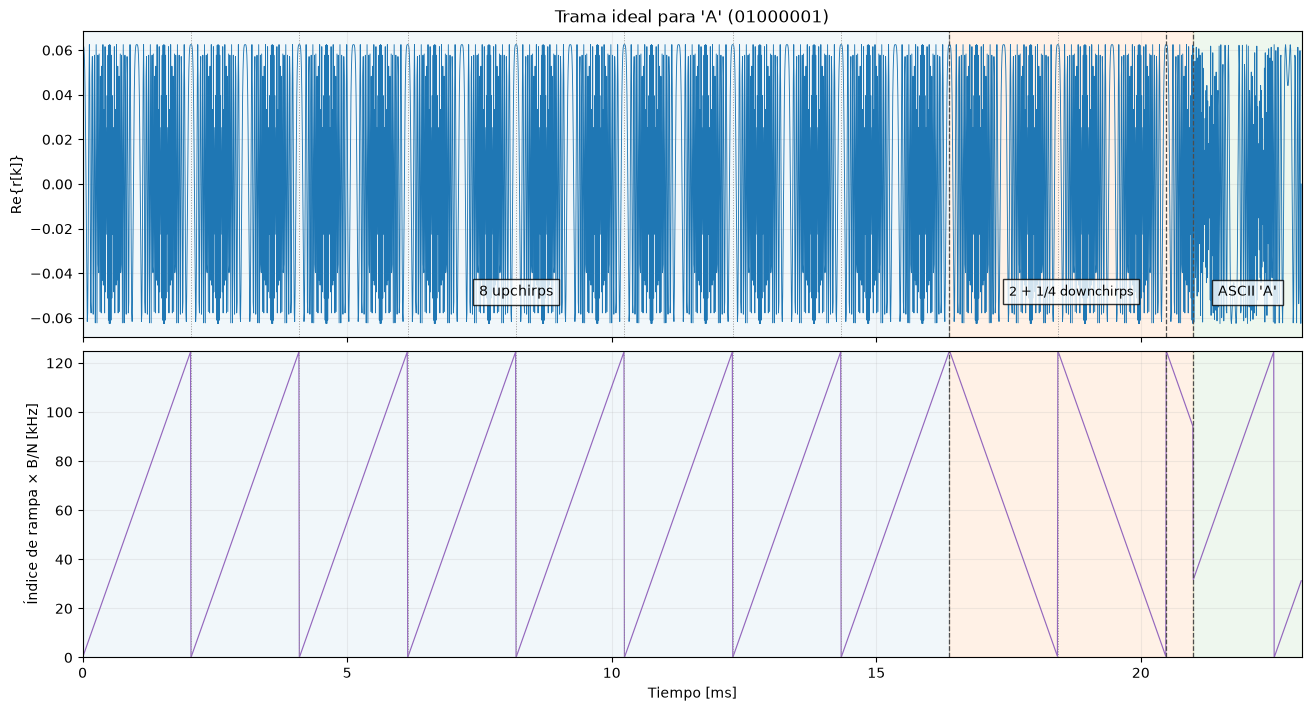

In [26]:
# Mostramos la señal y su rampa para ubicar visualmente las partes de la trama.
rampa_up = k * B / N
rampa_down = B - rampa_up  # B y 0 son el mismo borde en frecuencia discreta
rampa_payload = np.mod(valor_ascii + k, N) * B / N
rampa_trama = np.concatenate((np.tile(rampa_up, 8), rampa_down, rampa_down,
                              rampa_down[:N//4], rampa_payload))
assert len(rampa_trama) == len(recibida_ideal)
tiempo_ms = np.arange(len(recibida_ideal)) / B * 1e3

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
axes[0].plot(tiempo_ms, recibida_ideal.real, lw=0.65, color='tab:blue')
axes[0].set(ylabel='Re{r[k]}', title=f'Trama ideal para {caracter!r} ({bits_payload})')
axes[1].plot(tiempo_ms, rampa_trama / 1e3, lw=0.85, color='tab:purple')
axes[1].set(xlabel='Tiempo [ms]', ylabel='Índice de rampa × B/N [kHz]')

for ax in axes:
    ax.axvspan(0, limites[1]/B*1e3, color='tab:blue', alpha=0.06)
    ax.axvspan(limites[1]/B*1e3, limites[3]/B*1e3, color='tab:orange', alpha=0.10)
    ax.axvspan(limites[3]/B*1e3, limites[4]/B*1e3, color='tab:green', alpha=0.08)
    for muestra in np.arange(N, 10*N, N):
        ax.axvline(muestra/B*1e3, color='0.6', ls=':', lw=0.7)
    for muestra in limites[1:-1]:
        ax.axvline(muestra/B*1e3, color='0.3', ls='--', lw=0.9)
    ax.grid(True, alpha=0.2)

axes[0].text(limites[1]/(2*B)*1e3, -0.05, '8 upchirps', ha='center', bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[1]+limites[3])/(2*B)*1e3, -0.05, '2 + 1/4 downchirps', ha='center', fontsize=9, bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[3]+limites[4])/(2*B)*1e3, -0.05, f'ASCII {caracter!r}', ha='center', bbox={'facecolor': 'white', 'alpha': 0.8})
axes[1].set_ylim(0, B/1e3)
axes[1].set_xlim(0, len(recibida_ideal)/B*1e3)
plt.show()

## 3. Detección temporal por correlación

El receptor observa `[ceros, trama, ceros]`, con márgenes aleatorios: debe encontrar el inicio sin conocerlo. Guardamos `inicio_verdadero` sólo para evaluar el resultado.

### 3.1. Encontrar la cabecera sin ruido


In [27]:
# Agregamos márgenes impares para probar un inicio no alineado con los símbolos.
generador_margenes = np.random.default_rng()
muestras_antes = int(2 * generador_margenes.integers(0, N) + 1)
muestras_despues = int(2 * generador_margenes.integers(0, N) + 1)
bloque_recibido = np.concatenate((np.zeros(muestras_antes, dtype=complex),
                                 recibida_ideal, np.zeros(muestras_despues, dtype=complex)))
inicio_verdadero = muestras_antes  # sólo para verificar, no para detectar
fin_verdadero = inicio_verdadero + len(recibida_ideal)
print(f'Bloque: {len(bloque_recibido)} muestras | inicio verdadero: {inicio_verdadero}')


Bloque: 3258 muestras | inicio verdadero: 281


Buscamos la cabecera conocida (8 upchirps + 2¼ downchirps) comparando su plantilla con una ventana del bloque recibido para cada inicio candidato $m$. La correlación mide cuánto coinciden ambas formas; la normalizamos por sus energías para que una mayor amplitud no implique por sí sola una mejor coincidencia. Así obtenemos un puntaje para cada posible inicio:

$$C[m]=\frac{\left|\sum_{n=0}^{L-1}r[m+n]h^*[n]\right|^2}
{\left(\sum_{n=0}^{L-1}|h[n]|^2\right)\left(\sum_{n=0}^{L-1}|r[m+n]|^2\right)}.$$

El **numerador** es la magnitud al cuadrado de la correlación entre `plantilla` y la `ventana` que empieza en `m`: `abs(coincidencia) ** 2`. El **denominador** es el producto de sus energías: `energia_plantilla * energia_ventana`.

Una coincidencia ideal da $C=1$; elegimos el máximo de `puntajes[m]` y comprobamos que supera el umbral. El payload queda fuera de la plantilla porque todavía no lo conocemos.


In [28]:
# Comparamos cada ventana con la plantilla para estimar el inicio de la cabecera.
def puntajes_correlacion(bloque, plantilla):
    """Correlación normalizada para todos los inicios posibles."""
    if len(bloque) < len(plantilla):
        raise ValueError('El bloque debe contener al menos una plantilla completa')
    energia_plantilla = np.vdot(plantilla, plantilla).real
    puntajes = np.zeros(len(bloque) - len(plantilla) + 1)

    for m in range(len(puntajes)):
        ventana = bloque[m:m + len(plantilla)]
        energia_ventana = np.vdot(ventana, ventana).real
        if energia_ventana > 0:  # evita dividir por cero en el reposo
            coincidencia = np.vdot(plantilla, ventana)
            puntajes[m] = abs(coincidencia) ** 2 / (energia_plantilla * energia_ventana)
    return puntajes


cabecera_conocida = np.concatenate((preambulo, sincronizacion))
puntajes_preambulo = puntajes_correlacion(bloque_recibido, preambulo)
puntajes_cabecera = puntajes_correlacion(bloque_recibido, cabecera_conocida)

mejor_inicio = int(np.argmax(puntajes_cabecera))
mejor_puntaje = puntajes_cabecera[mejor_inicio]
umbral_ideal = 1 - 1e-10  # coincidencia casi perfecta, sólo para el caso ideal
existe_trama = bool(mejor_puntaje >= umbral_ideal)
inicio_detectado = mejor_inicio if existe_trama else None

# Caso de control: un bloque del mismo tamaño pero sin ninguna trama.
bloque_sin_trama = np.zeros_like(bloque_recibido)
puntajes_sin_trama = puntajes_correlacion(bloque_sin_trama, cabecera_conocida)
existe_en_control = bool(np.max(puntajes_sin_trama) >= umbral_ideal)

assert existe_trama and inicio_detectado == inicio_verdadero
assert not existe_en_control
print(f'Inicio detectado: {inicio_detectado} | Cmáx: {mejor_puntaje:.4f}'
      f' | Detección en bloque vacío: {existe_en_control}')


Inicio detectado: 281 | Cmáx: 1.0000 | Detección en bloque vacío: False


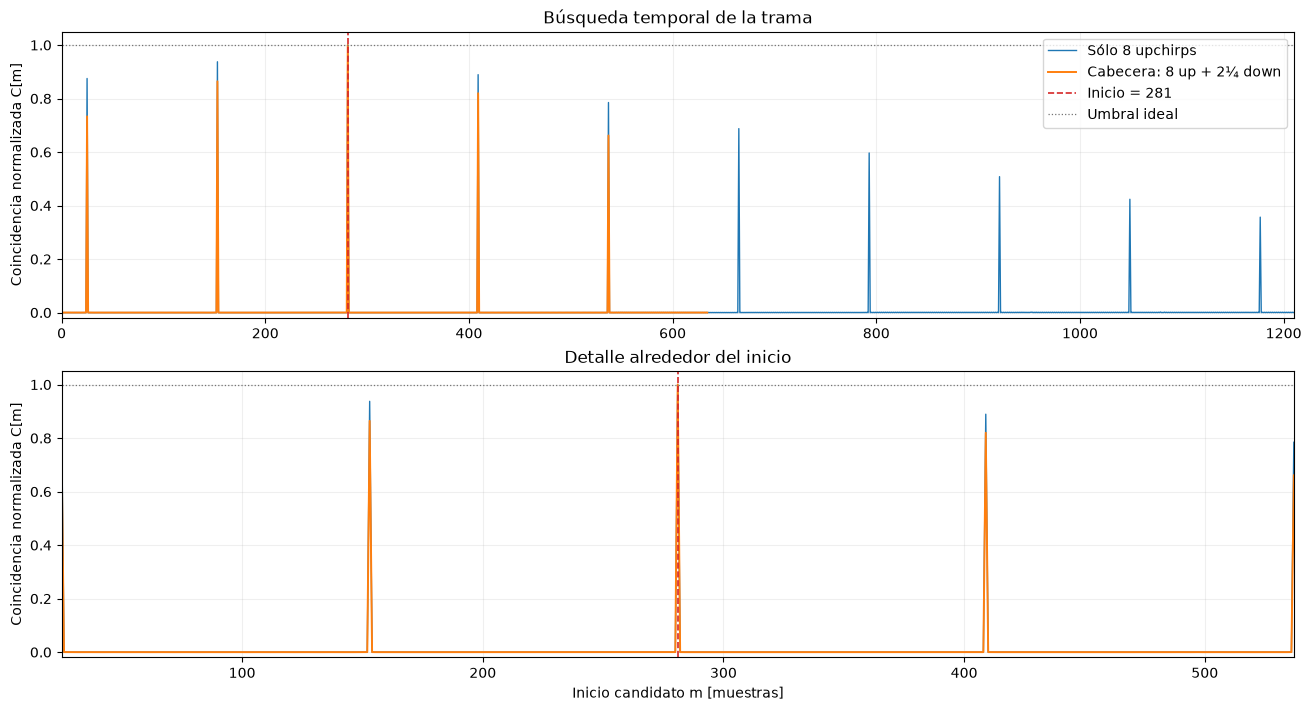

In [29]:
# Comparamos las plantillas y ampliamos el pico para ver cuál identifica el inicio.
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharey=True, constrained_layout=True)
for ax in axes:
    ax.plot(np.arange(len(puntajes_preambulo)), puntajes_preambulo,
            lw=1, color='tab:blue', label='Sólo 8 upchirps')
    ax.plot(np.arange(len(puntajes_cabecera)), puntajes_cabecera,
            lw=1.4, color='tab:orange', label='Cabecera: 8 up + 2¼ down')
    ax.axvline(inicio_detectado, color='tab:red', ls='--', lw=1.2,
               label=f'Inicio = {inicio_detectado}')
    ax.axhline(umbral_ideal, color='0.45', ls=':', lw=0.9, label='Umbral ideal')
    ax.set(ylabel='Coincidencia normalizada C[m]', ylim=(-0.02, 1.05))
    ax.grid(True, alpha=0.2)

axes[0].set(title='Búsqueda temporal de la trama', xlim=(0, len(puntajes_preambulo) - 1))
axes[0].legend(loc='upper right')
axes[1].set(xlabel='Inicio candidato m [muestras]',
            xlim=(max(0, inicio_detectado - N), inicio_detectado + N),
            title='Detalle alrededor del inicio')
plt.show()


La cabecera completa permite distinguir el inicio entre los picos del preámbulo repetido. En la fórmula usada en clase, el upchirp repite su mitad y aparecen picos separados por `N/2`; cada símbolo sigue teniendo `N` muestras.


### 3.2. Leer el payload sin ruido

Avanzamos la longitud de la cabecera desde el inicio detectado y leemos las siguientes `N` muestras con dechirp + FFT. Esperamos recuperar `65 → 01000001 → A`.


In [30]:
# Leemos el símbolo desde el inicio estimado; esta función también servirá con ruido.
def leer_payload(bloque, inicio):
    if inicio is None:
        return None
    inicio_dato = inicio + len(cabecera_conocida)
    payload = bloque[inicio_dato:inicio_dato + N]
    return demodular_simbolo(payload)[0] if len(payload) == N else None


valor_recuperado = leer_payload(bloque_recibido, inicio_detectado)
if valor_recuperado is None:
    raise ValueError('Falta la cabecera detectada o el payload completo')
bits_recuperados = f'{valor_recuperado:0{SF}b}'
caracter_recuperado = chr(valor_recuperado)
print(f'Payload: {valor_recuperado} → {bits_recuperados} → {caracter_recuperado!r}')
assert valor_recuperado == valor_ascii and bits_recuperados == bits_payload


Payload: 65 → 01000001 → 'A'


### 3.3. Repetir con ruido

Sumamos ruido gaussiano blanco complejo a **todo** el bloque: $r[n]=x[n]+w[n]$. La SNR usa la potencia de la trama activa, sin los ceros. Repetimos la correlación con un umbral manual (`0.01`), porque el puntaje ya no será 1.

*Nota:* dejamos la detección por energía y la calibración de falsas alarmas para otra etapa.


In [31]:
# Aceptamos el pico sólo si supera el umbral y leemos el dato desde ese inicio.
umbral_ruido = 0.01  # manual, todavía no calibrado
potencia_trama = np.mean(np.abs(trama_transmitida) ** 2)


def detectar_payload(bloque, umbral):
    puntajes = puntajes_correlacion(bloque, cabecera_conocida)
    candidato = int(np.argmax(puntajes))
    inicio = candidato if puntajes[candidato] > umbral else None
    return inicio, leer_payload(bloque, inicio), puntajes


SNR: -7 dB | Cmáx: 0.1713 | Inicio: 281 (real: 281) | Símbolo: 65 | Paquete correcto: True


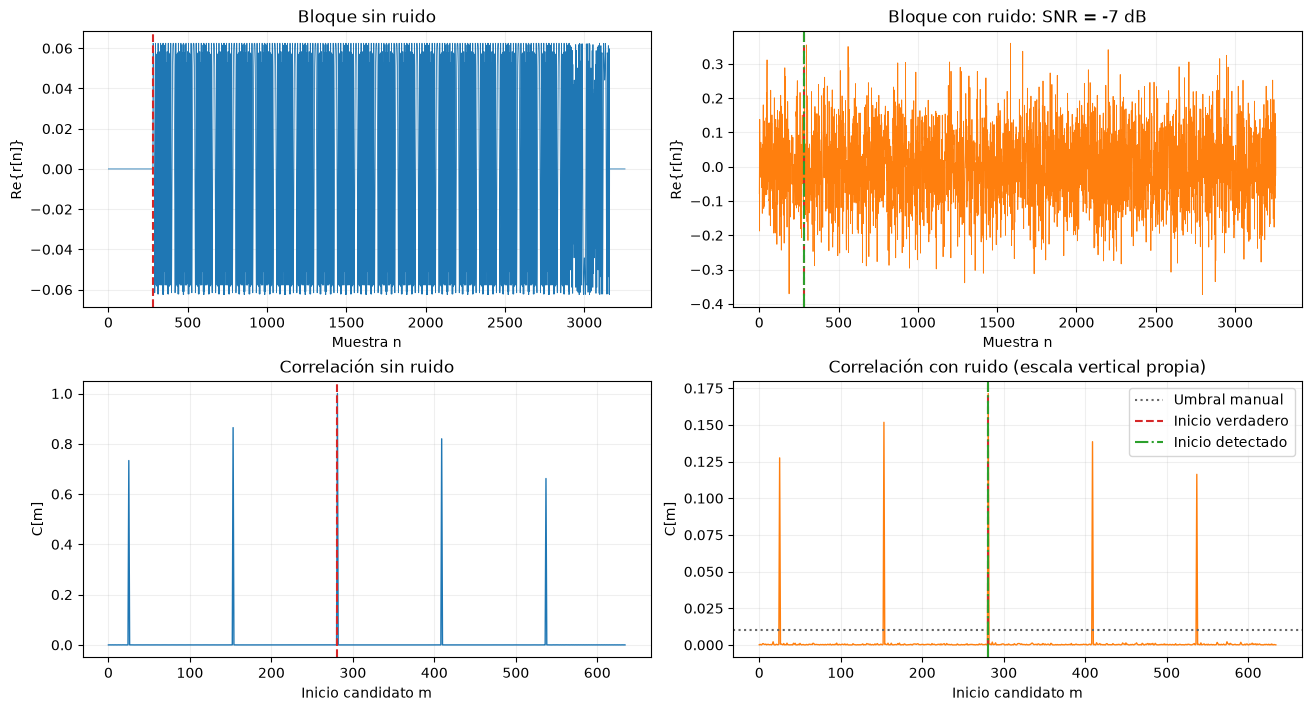

In [32]:
# Sumamos ruido al bloque y comparamos el inicio y el dato con el caso ideal.
snr_ejemplo_db = -7  # volver a ejecutar con otra SNR para comparar
generador_ruido = np.random.default_rng(2026)
potencia_ruido, sigma = parametros_ruido_desde_snr(snr_ejemplo_db, potencia_trama)
bloque_con_ruido, ruido = agregar_ruido_awgn(bloque_recibido, sigma, generador_ruido)

inicio_con_ruido, valor_con_ruido, puntajes_con_ruido = detectar_payload(
    bloque_con_ruido, umbral_ruido)
paquete_correcto = (inicio_con_ruido == inicio_verdadero and valor_con_ruido == valor_ascii)

print(f'SNR: {snr_ejemplo_db} dB | Cmáx: {puntajes_con_ruido.max():.4f}'
      f' | Inicio: {inicio_con_ruido} (real: {inicio_verdadero})'
      f' | Símbolo: {valor_con_ruido} | Paquete correcto: {paquete_correcto}')

fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
axes[0, 0].plot(bloque_recibido.real, lw=0.6)
axes[0, 0].set(title='Bloque sin ruido', ylabel='Re{r[n]}', xlabel='Muestra n')
axes[0, 1].plot(bloque_con_ruido.real, lw=0.6, color='tab:orange')
axes[0, 1].set(title=f'Bloque con ruido: SNR = {snr_ejemplo_db} dB',
               ylabel='Re{r[n]}', xlabel='Muestra n')
axes[1, 0].plot(puntajes_cabecera, lw=1)
axes[1, 0].set(title='Correlación sin ruido', ylabel='C[m]', xlabel='Inicio candidato m')
axes[1, 1].plot(puntajes_con_ruido, lw=1, color='tab:orange')
axes[1, 1].axhline(umbral_ruido, color='0.4', ls=':', label='Umbral manual')
axes[1, 1].set(title='Correlación con ruido (escala vertical propia)',
               ylabel='C[m]', xlabel='Inicio candidato m')
for ax in axes.flat:
    ax.axvline(inicio_verdadero, color='tab:red', ls='--', label='Inicio verdadero')
    ax.grid(True, alpha=0.2)
if inicio_con_ruido is not None:
    for ax in axes[:, 1]:
        ax.axvline(inicio_con_ruido, color='tab:green', ls='-.', label='Inicio detectado')
axes[1, 1].legend()
plt.show()


### 3.4. Medir PER frente a SNR

Repetimos con distintos ruidos e inicios. Un paquete falla si no se detecta, si el inicio es incorrecto o si el dato se recupera mal; lo contamos una sola vez:

$$\mathrm{PER}=\frac{\text{paquetes fallidos}}{\text{paquetes transmitidos}}.$$

Exigimos inicio exacto y mantenemos el mismo payload y largo de bloque. Como referencia, también leemos el dato con el inicio conocido, usando el mismo ruido. `paquetes_por_snr` controla cuántos ensayos hacemos.


In [33]:
# Repetimos por SNR y contamos las causas de error para estimar la PER.
snrs_db = np.array([-30, -25, -20, -18, -15, -12, -10, -5, 0])
paquetes_por_snr = 1000
generador_per = np.random.default_rng(2027)
resultados_per = []

print(' SNR   No detecta  Inicio mal  Dato mal  Errores/total    PER  PER inicio conocido')
for snr_db in snrs_db:
    _, sigma_per = parametros_ruido_desde_snr(snr_db, potencia_trama)
    no_detectados = inicios_erroneos = datos_erroneos = errores_referencia = 0

    for _ in range(paquetes_por_snr):
        inicio_real = int(2 * generador_per.integers(0, N) + 1)
        bloque_limpio = np.concatenate((
            np.zeros(inicio_real, dtype=complex), trama_transmitida,
            np.zeros(2 * N - inicio_real, dtype=complex)))
        recibido, _ = agregar_ruido_awgn(bloque_limpio, sigma_per, generador_per)
        inicio_estimado, dato_estimado, _ = detectar_payload(recibido, umbral_ruido)

        # Clasificación excluyente: cada paquete fallido se cuenta una sola vez.
        if inicio_estimado is None:
            no_detectados += 1
        elif inicio_estimado != inicio_real:
            inicios_erroneos += 1
        elif dato_estimado != valor_ascii:
            datos_erroneos += 1

        # Referencia con sincronización conocida; no interviene en el detector.
        dato_referencia = leer_payload(recibido, inicio_real)
        errores_referencia += int(dato_referencia != valor_ascii)

    errores = no_detectados + inicios_erroneos + datos_erroneos
    per = errores / paquetes_por_snr
    per_referencia = errores_referencia / paquetes_por_snr
    tasa_fallo_inicio = (no_detectados + inicios_erroneos) / paquetes_por_snr
    resultados_per.append((snr_db, per, per_referencia, tasa_fallo_inicio))
    assert 0 <= per_referencia <= per <= 1
    print(f'{snr_db:4.0f} {no_detectados:11d} {inicios_erroneos:11d} {datos_erroneos:9d}'
          f' {errores:5d}/{paquetes_por_snr:<5d} {per:7.3f} {per_referencia:20.3f}')


 SNR   No detecta  Inicio mal  Dato mal  Errores/total    PER  PER inicio conocido
 -30        1000           0         0  1000/1000    1.000                0.996
 -25         998           0         2  1000/1000    1.000                0.970
 -20         486          38       410   934/1000    0.934                0.848
 -18          25          46       622   693/1000    0.693                0.660
 -15           0           6       231   237/1000    0.237                0.232
 -12           0           0        17    17/1000    0.017                0.017
 -10           0           0         0     0/1000    0.000                0.000
  -5           0           0         0     0/1000    0.000                0.000
   0           0           0         0     0/1000    0.000                0.000


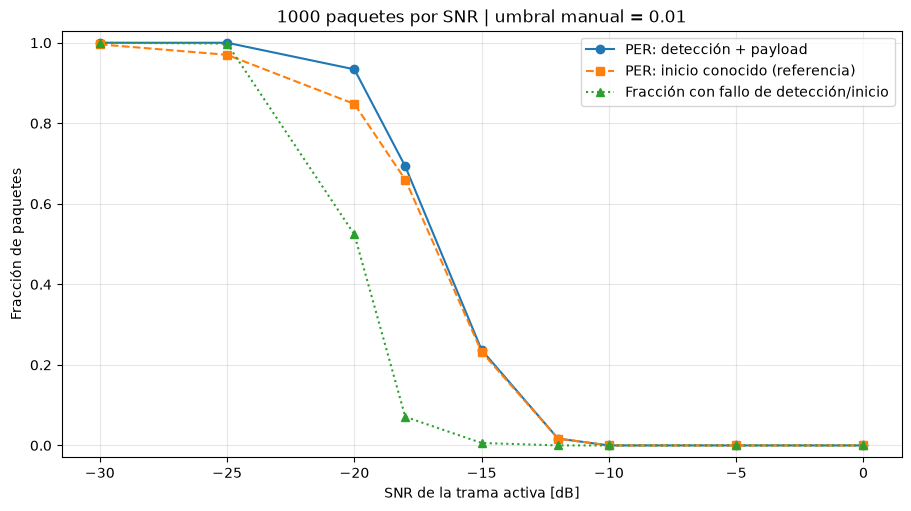

In [34]:
# Comparamos la PER completa con la referencia de inicio conocido.
resultados_per = np.asarray(resultados_per)
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.plot(resultados_per[:, 0], resultados_per[:, 1], 'o-', label='PER: detección + payload')
ax.plot(resultados_per[:, 0], resultados_per[:, 2], 's--', label='PER: inicio conocido (referencia)')
ax.plot(resultados_per[:, 0], resultados_per[:, 3], '^:', label='Fracción con fallo de detección/inicio')
ax.set(xlabel='SNR de la trama activa [dB]', ylabel='Fracción de paquetes',
       title=f'{paquetes_por_snr} paquetes por SNR | umbral manual = {umbral_ruido}',
       ylim=(-0.03, 1.03))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


La diferencia entre las curvas muestra cuánto agrega la detección a los errores del dato. Una PER de cero indica que no hubo errores **en esos ensayos**. Evaluamos sólo AWGN, sin desajustes de frecuencia o reloj, y con umbral manual.
